# Unterrichtsbeispiel

[&larr; Einführung](01_VEKTORRECHNUNG.ipynb)

## Motivation

Ein typisches Anwendungsgebiet der Vektorrechnung ist die Robotik (und ganz allgemein die Mechanik). In der Robotik wird die Vektorrechnung eingesetzt, um zum Beispiel die Greiferposition bzw. die Positionen der einzelnen Gelenke zu bestimmen (im dreidimensionalen Raum). Bei Robotern mit vielen Gelenken hat die Verwendung von Vektoren grosse Vorteile.

---

## Aufgabe

Wir wollen die Bewegung eines Roboterarms mit zwei Drehgelenken (zwei Freiheitsgrade) berechnen, wobei wir mit Vektoren arbeiten wollen. Gesucht ist die Position des Greifers (*End Effector*) in Abhängigkeit der Gelenkwinkel $\varphi_1$ und $\varphi_2$. 

Gegeben sind die Längen $l_1$ und $l_2$ der beiden Arme sowie der Zeitverlauf der Gelenkwinkel in der Datei `angles.txt`. 

<center>
    <img src="img/robot.svg" width=70% />
</center><br>

☝🏼 Wir beschränken uns hier bewusst auf den zweidimensionalen (2D) Fall, damit wir die Ergebnisse leicht nachvollziehen können. Das Vorgehen wäre bei einem 3D-Roboter aber vom Prinzip her gleich.

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

l_1 = 1.0  # Länge [m] des ersten Arms
l_2 = 0.5  # Länge [m] des zweiten Arms

p_1_0 = np.array([l_1, 0])
p_2_0 = np.array([l_2, 0])

### a) Drehwinkel einlesen

Die Gelenkwinkel $\varphi_1$ bzw. $\varphi_2$ sind im Textfile `angles.txt` abgelegt (für jeden Zeitschritt). Dieses soll mit NumPy eingelesen werden und entsprechende Arrays `t`, `phi_1` und `phi_2` erstellt werden. Ebenfalls soll die Variable `N` erstellt werden für die Anzahl der Zeitschritte.

In [2]:
data = np.loadtxt('data/angles.txt')
t = data[:,0]
phi_1 = data[:,1]
phi_2 = data[:,2]

N = len(data)  # alternativ N = data.shape[0]

# t, phi_1, phi_2 = data.T

### b) Drehmatrix aufstellen

Die Rotationsmatrix in 2D ist eine 2x2-Matrix mit entsprechenden Einträgen ($\cos(\varphi), \sin(\varphi)$ etc., vgl. Theorienotebook) und soll hier als Funktion `R(phi)` definiert werden.

$$R(\varphi)=\left[\begin{array}{cc}\cos(\varphi) & -\sin(\varphi) \\ \sin(\varphi) & \cos(\varphi)\end{array}\right]$$

In [3]:
def R(phi):
    return np.array([[np.cos(phi), -np.sin(phi)],
                     [np.sin(phi), np.cos(phi)]])

### c) Berechnung der Greiferposition

Die Positionen des Gelenkes $\vec{p}_1$ und des Greifers $\vec{p}_2$ sollen für alle Zeitpunkte bzw. Gelenkwinkel $\varphi_1$ bzw. $\varphi_2$ berechnet werden. Die Drehung eines Vektors $\vec p$ erfolgt durch die Matrixmultiplikation der Rotationsmatrix mit dem Vektor: $R(\varphi) \cdot \vec p$.

☝🏼 Für die Matrixmultiplikation wird in NumPy der @-Operator verwendet (oder alternativ `np.matmul()`).

In [4]:
p_1 = np.zeros((N, 2))
p_2 = np.zeros((N, 2))

for i in range(N):
    p_1[i] = R(phi_1[i]) @ p_1_0 
    p_2[i] = p_1[i] + R(phi_1[i]) @ R(phi_2[i]) @ p_2_0
   #p_2[i] = R(phi_1[i]) @ (p_1_0 + R(phi_2[i]) @ p_2_0)  

### d) Grafische Darstellung des Roboterarms

Der Positionsverlauf des Greifers soll grafisch in einem Diagramm dargestellt werden. Der Roboterarm soll dabei in der Grundposition (Position zum Zeitpunkt 0) dargestellt werden.

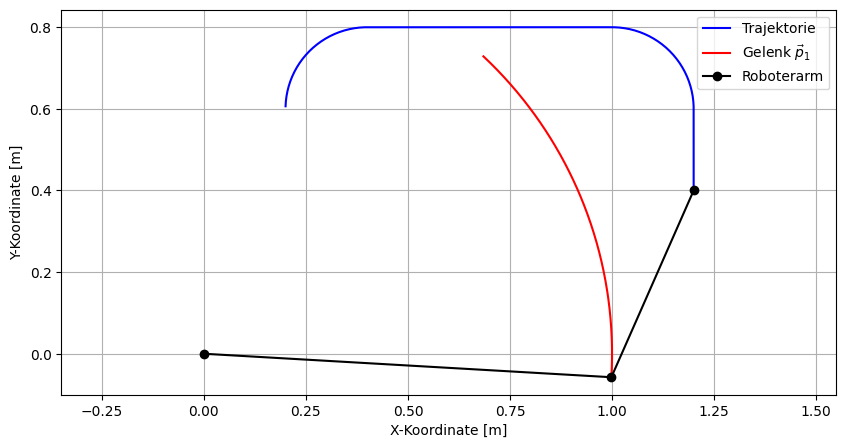

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(p_2[:,0], p_2[:,1], 'b', label='Trajektorie')
ax.plot(p_1[:,0], p_1[:,1], 'r', label=r'Gelenk $\vec{p}_1$')
line, = ax.plot([0, p_1[0,0], p_2[0,0]] , [0, p_1[0,1], p_2[0,1]], 'k-o', label='Roboterarm')

ax.axis('equal')
ax.set_xlabel('X-Koordinate [m]')
ax.set_ylabel('Y-Koordinate [m]')
ax.grid()
ax.legend()
plt.show()

### e) Animation der Roboterbewegung

In einer Animation soll die Roboterposition nun für alle Zeitschritte dargestellt werden (Bewegungsablauf) und als GIF exportiert werden. Da wir in der Animation nur den Roboterarm verändern müssen (alles andere des Diagramms bleibt identisch), weisen wir die Roboterarm-Kurve im obigen Codeblock explizit einer Variablen zu (vgl. `line, = ax.plot(...)`), damit wir diese im Animationsloop verändern können. 

In [6]:
import matplotlib.animation as animation

def update(frame):
    line.set_data([0, p_1[frame,0], p_2[frame,0]],
                  [0, p_1[frame,1], p_2[frame,1]])
    return line

ani = animation.FuncAnimation(fig=fig, func=update, frames=N, interval=40)
ani.save('Robot.gif')

Zusatz: Durch numerisches Ableiten des Positionsverlaufs kann der Geschwindigkeitsverlauf berechnet werden.

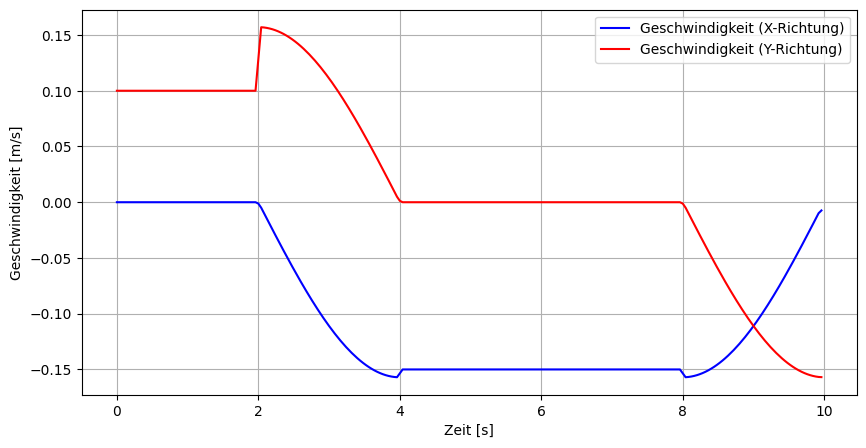

In [7]:
v = np.gradient(p_2, t, axis=0)  # Ableitung (Gradient = Steigung)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, v[:,0], 'b', label='Geschwindigkeit (X-Richtung)')
ax.plot(t, v[:,1], 'r', label='Geschwindigkeit (Y-Richtung)')
ax.set_xlabel('Zeit [s]')
ax.set_ylabel('Geschwindigkeit [m/s]')
ax.grid()
ax.legend()
plt.show()